# 05-04 - Street Level

You read a street photograph the way a walk audit does, through the label map of a network trained on the streets of fifty cities, and count what it sees.

We start with one image. Then we read its label map, count the shares of the nineteen classes, compute the green view index and the sky share, zoom into where the labels fail, and look at the cell that would run the network on your own picture. At the end you count another class.

Before you run anything, choose *File*, then *Save As*, and give the copy a name with `-mywork` in it, so that the next pull never collides with your work.

In [1]:
import json

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import seg_tools as seg

plt.rcParams["figure.dpi"] = 72

scene = seg.load_scene("data/scene.json")
reference = json.load(open("data/ground_truth.json"))["p05"]
torch_ok = seg.torch_available()
print(f"the window of {scene['window']['date']}: {scene['window']['pixels']:,} pixels a side at "
      f"{scene['window']['resolution_m']} m, {scene['blocks']['n']} blocks, "
      f"{scene['chips']['tiled']['total']:,} chips; the deep learning library is "
      f"{'ready' if torch_ok else 'missing, so the cells that need it are skipped'}")

the window of 2023-08-20: 10,240 pixels a side at 0.3 m, 25 blocks, 1,600 chips; the deep learning library is ready


## One street image

The cell reads the image and its label map with the class names and the palette, and shows the image with its credit.

image 1211673680555546 of Nassau Street, downtown, captured 2024-11-11, 2048 by 1536 pixels
Mapillary contributors, CC BY-SA 4.0, image 1211673680555546, captured 11 November 2024
the label map has 512 by 384 cells in 19 classes


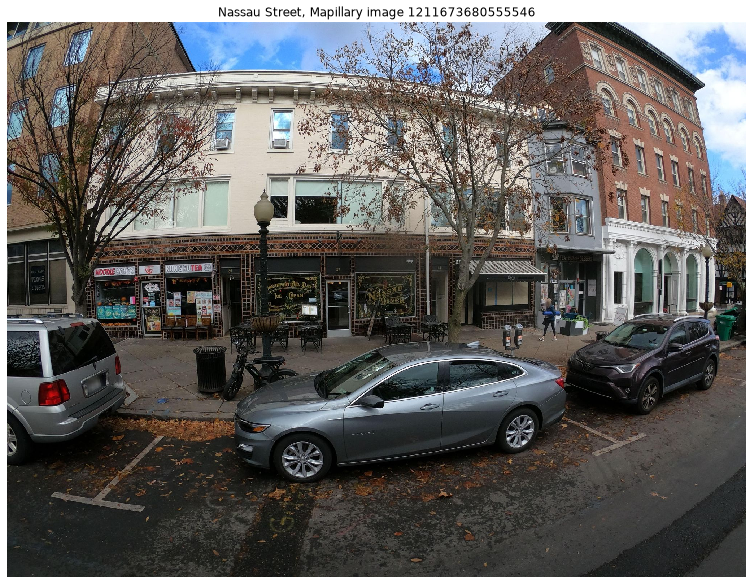

In [2]:
image, labels, names, palette, z = seg.read_street("data/street_nassau.jpg", "data/street_nassau.npz")
street = scene["choices"]["street"]
print(f"image {z['image']} of {street['label']}, captured {street['date']}, "
      f"{image.shape[1]} by {image.shape[0]} pixels")
print(street["credit"])
print(f"the label map has {labels.shape[1]} by {labels.shape[0]} cells in {len(names)} classes")
fig, ax = plt.subplots(figsize=(14, 10))
seg.show_image(ax, image, f"Nassau Street, Mapillary image {z['image']}")

A forward-facing frame from a camera on a car, uploaded to Mapillary under an open licence by one contributor on a November day. Faces and plates were blurred by the platform before anybody saw it, and the credit line is part of the data. The label map is a quarter of the picture's size on each side, because the network answers on a coarser grid than it reads. The trees are bare, so the green index below is a November number. A summer frame would give another.

## The label map

The cell draws the image beside its label map in the colours of the Cityscapes classes, with the largest classes in the legend.

road, sidewalk, building, wall, fence, pole, traffic light, traffic sign, vegetation, terrain, sky, person, rider, car, truck, bus, train, motorcycle, bicycle


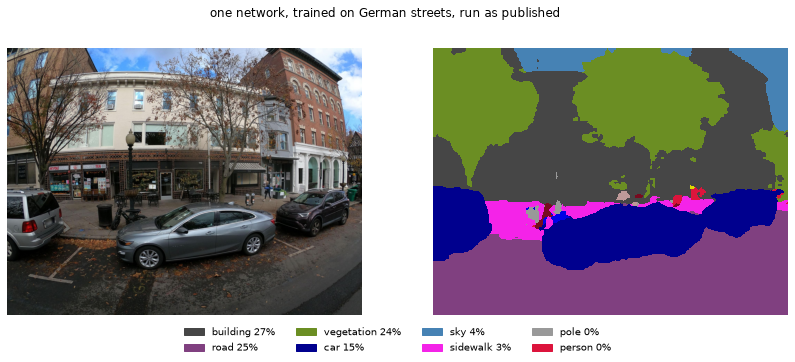

In [3]:
fig = seg.show_street(image, labels, palette, names,
                      "one network, trained on German streets, run as published")
print(", ".join(names))

The network is SegFormer, a transformer segmenter in its smallest size, 3.7 million weights, trained on five thousand finely labelled street scenes from fifty cities, most of them German. It answers in nineteen classes and no others, listed in the printed line: road and sidewalk, building and wall, pole and sign, vegetation and terrain, sky, person and rider, and the vehicles. It was run exactly as published, without a single Princeton label. Look at the colours along the kerb and under the awnings, where the classes meet.

## Shares and the green view index

The cell counts the share of the map's cells in every class, and reads the green view index and the sky share from them.

In [4]:
shares = seg.class_shares(labels, names)
green = seg.green_view_index(labels, names)
ref_ = reference["street"]
print(f"green view index {green:.1%}, sky {shares['sky']:.1%}"
      f"   reference {ref_['green_view_index']:.1%} and {ref_['sky']:.1%}")
print(f"the street over {ref_['images_street']} images of the same day: "
      f"green {ref_['green_view_index_street']:.1%}, sky {ref_['sky_street']:.1%}")
for name, value in list(shares.items())[:8]:
    print(f"{name:14} {value:6.1%}")

green view index 24.2%, sky 4.3%   reference 24.2% and 4.3%
the street over 6 images of the same day: green 21.1%, sky 23.7%
building        27.2%
road            25.4%
vegetation      24.2%
car             14.7%
sky              4.3%
sidewalk         3.2%
pole             0.3%
person           0.2%


The green view index is the share of a picture's pixels that the network calls vegetation, an index proposed for walk audits and first measured with a segmenter in 2015. The sky share is the share it calls sky. This frame has more green than the street's average over six frames, because it faces a row of street trees. The table lists every class above a trace. Which classes count as green is a decision to write down, and terrain, the grass beside the road, is counted apart here.

## Where the labels fail

The cell enlarges the label map to the picture's size and lays it over the lower left quarter, where the kerb, the parked cars and the shopfronts meet.

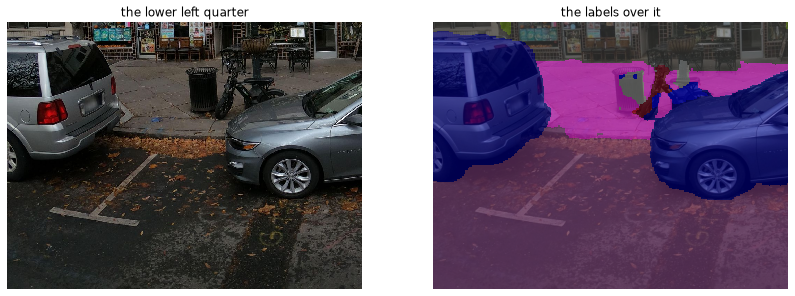

In [5]:
scale = image.shape[0] // labels.shape[0]
big = np.repeat(np.repeat(labels, scale, axis=0), scale, axis=1)
h, w = image.shape[0] // 2, image.shape[1] // 2
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
seg.show_image(axes[0], image[h:, :w], "the lower left quarter")
axes[1].imshow(image[h:, :w])
seg.show_image(axes[1], palette[big[h:, :w]], "the labels over it")
axes[1].images[-1].set_alpha(0.55)

Look for three kinds of error. The kerb and the first strip of the road read as sidewalk, or the sidewalk as road, because the two classes meet at a line the network guesses at a quarter of the picture's resolution. A shopfront's awning reads as building, which it is, and the flower boxes under it as vegetation, which they are. None of these move the green index much, and all of them would move a count of parked cars. The errors decide what a model can count.

## The live lane

The cell is the recipe that drew the label map, switched off. It needs the transformers library and a download of the weights, neither in the course environment.

In [6]:
RUN_LIVE = False
if RUN_LIVE:
    from transformers import SegformerForSemanticSegmentation, SegformerImageProcessor
    name = "nvidia/segformer-b0-finetuned-cityscapes-1024-1024"
    processor = SegformerImageProcessor.from_pretrained(name)
    network = SegformerForSemanticSegmentation.from_pretrained(name).eval()
    print("the network is loaded, see the paragraph below for the three lines that label a picture")
else:
    print("the live lane is off, the label map above was computed with this recipe on the course's laptop")

the live lane is off, the label map above was computed with this recipe on the course's laptop


To label a picture of your own, install transformers in a scratch environment, set the switch to True, and run the picture through the processor and the network. The processor scales it and normalises its colours, the network scores every class per cell, and the largest score is the label. The weights come from the model hub under a research licence, so the kit ships the label map, not the network. A project that uses this on Princeton photographs adds a few labelled frames of its own first.

## Your turn

The index counts vegetation. Count another class of the nineteen instead, the sidewalk, the one a walk audit cares about next. Run the cell as it is, then change the marked value and run it again.

Is the sidewalk share a number you would trust from this frame, and what in the fourth section says why? Write your answer in one or two sentences. The answer comes in Friday's post, not in the kit.

In [7]:
CLASS = "vegetation"  # change me: "sidewalk"
share = seg.green_view_index(labels, names, green=(CLASS,))
print(f"{CLASS}: {share:.1%} of the picture's cells")

vegetation: 24.2% of the picture's cells


## Check your understanding

1. The green view index of this frame is higher than the street's average over six frames. Name two reasons a single frame can mislead.
2. Why does the label map have a quarter of the picture's resolution, and which errors does that cause?
3. The network was trained on German streets. What is the dataset shift here, and what would a project do about it first?
4. Which classes would you count as green for a walk audit, and why must the choice be written down?

## Where we are

You have read one street frame through a published segmenter, counted its nineteen classes, computed the green view index and the sky share, and seen where the labels fail along the kerb and under the awnings. You now know what a walk audit counts, what moves the count, and why the picture's date belongs beside it. That closes the kit. The project brief says what a poster states about a mask.

## Further resources

Nothing in this course requires anything below.

- Handbook of Geospatial Artificial Intelligence, chapter 17 on street-level imagery, Filip Biljecki, in Gao, Hu and Li, eds., CRC Press, 2024
- SegFormer: simple and efficient design for semantic segmentation with transformers, Enze Xie and colleagues, NeurIPS 2021, https://arxiv.org/abs/2105.15203
- Mapillary, the platform and its API documentation, https://www.mapillary.com/developer

The model, its weights, its outputs and this kit are the course's own work, published under CC BY 4.0. The imagery is NAIP 2023 of the USDA, public domain, read from the Planetary Computer. The street image is by a Mapillary contributor, licensed CC BY-SA 4.0, image 1211673680555546 of 11 November 2024, with faces and plates blurred by the platform; the label map comes from SegFormer-B0 with the Cityscapes weights of NVIDIA.